# 23N Field Tests #04 — Ask India's Payments Data, in Hindi or English

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/23nlabs/field-tests/blob/main/ft04-ask-upi-data/ft04_ask_upi_data.ipynb)

**Question.** Can a small open model, running free, answer plain-language questions about India's UPI payments data
accurately, in Hindi (Devanagari) as well as in English? We give a ~3B-parameter open-weights model
(`Qwen2.5-Coder-3B-Instruct`) the table schema. It writes SQL, the notebook validates and runs that SQL on SQLite,
and each answer comes back with a chart and a one-line summary. We score it on 25 questions with reference
("gold") SQL: 12 in English and 13 in Hindi. The score is **execution accuracy**, meaning the query returns the
same result as the gold query. We also record latency per question.

**Dataset.** UPI monthly product statistics published by NPCI: banks live on UPI, transaction volume (million)
and value (₹ crore), Jan 2024 → Oct 2026 (34 months). The notebook first tries a live fetch from npci.org.in. If that
fails, it uses a small snapshot CSV in this repo, transcribed from NPCI's published table (provenance in the README).
NPCI publishes these figures publicly but states no open-data licence for them. We redistribute only a small
factual snapshot, with attribution, for research and education. Model weights: Qwen2.5-Coder-3B-Instruct,
*Qwen Research* licence (non-commercial).

**Runtime.** About 8–12 min on a free Colab **T4 GPU** (Runtime → Change runtime type → T4), including about 2 min to
download the 6 GB model. Without a GPU, the notebook switches to the 1.5B model and runs slower.
No paid API keys are needed.

*An independent study on public data by 23N AI Labs. It is not affiliated with or endorsed by NPCI, RBI, or
any bank.*

## 1 · Setup

In [1]:
# CELL: system_deps
# libraqm and libfribidi give Pillow complex-script text shaping, which Hindi needs.
# Install them before Pillow is imported.
!apt-get -qq install -y libraqm0 libfribidi0 > /dev/null 2>&1 || echo "apt not available, continuing"
%pip install -q gradio accelerate

In [2]:
# CELL: config
import os, sys, io, re, math, json, time, sqlite3, textwrap, unicodedata, subprocess, warnings, statistics
import urllib.request
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
warnings.filterwarnings("ignore", message="Glyph .* missing")

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/working")

# ---- Assumptions and knobs (all named, nothing hidden) ----
MODEL_ID = "Qwen/Qwen2.5-Coder-3B-Instruct"            # open weights, ~3.1B params, Qwen Research licence
CPU_FALLBACK_MODEL_ID = "Qwen/Qwen2.5-Coder-1.5B-Instruct"  # used automatically if no GPU
MAX_NEW_TOKENS = 256          # max SQL length generated
SELF_CORRECT_RETRIES = 1      # if SQL fails to run, show the model the error once and let it fix it
NUM_REL_TOL = 1e-3            # numbers in results match if within 0.1 % (or 0.01 absolute)
SQL_TIMEOUT_S = 5             # kill any query running longer than this
CLAUDE_MODEL = "claude-sonnet-5-5"  # optional comparison only, skipped without ANTHROPIC_API_KEY

# ---- Data sources ----
NPCI_URL = "https://www.npci.org.in/what-we-do/upi/product-statistics"   # official page (live attempt)
SNAPSHOT_LOCAL = "data/upi_monthly.csv"
SNAPSHOT_URL = "https://raw.githubusercontent.com/23nlabs/field-tests/main/ft04-ask-upi-data/data/upi_monthly.csv"
SNAPSHOT_RETRIEVED = "2026-11-09"
DB_PATH = "upi.db"

# ---- Brand ----
FT_NUM = "04"
BG, FG, ACCENT, TEAL = "#0B0F14", "#F5F7FA", "#FF7A1A", "#2EC4B6"
MUTED = "#8A94A6"; GRID = "#1E2630"
FONT = "DejaVu Sans"
plt.rcParams.update({"font.family": FONT, "figure.facecolor": BG, "axes.facecolor": BG,
                     "text.color": FG, "axes.labelcolor": FG, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.edgecolor": GRID})
print("Colab:", IN_COLAB, "| Kaggle:", IN_KAGGLE, "| matplotlib", matplotlib.__version__)

Colab: True | Kaggle: False | matplotlib 3.10.0


In [3]:
# CELL: fonts
# Hindi text. DejaVu Sans has no Devanagari glyphs, so we fetch Noto Sans Devanagari (SIL OFL) from the
# Google Fonts GitHub repo. This variable font also covers Latin and the ₹ sign.
# matplotlib < 3.11 does not do complex-script shaping (matras and conjuncts come out wrong), so every
# string containing Devanagari is rendered with Pillow + libraqm (HarfBuzz shaping) and pasted into
# figures as an image.
from PIL import Image, ImageDraw, ImageFont, features
FONT_DIR = "fonts"; os.makedirs(FONT_DIR, exist_ok=True)
DEVA_FONT = os.path.join(FONT_DIR, "NotoSansDevanagari-VF.ttf")
DEVA_FONT_URL = ("https://raw.githubusercontent.com/google/fonts/main/ofl/notosansdevanagari/"
                 "NotoSansDevanagari%5Bwdth%2Cwght%5D.ttf")
if not os.path.exists(DEVA_FONT):
    urllib.request.urlretrieve(DEVA_FONT_URL, DEVA_FONT)
fm.fontManager.addfont(DEVA_FONT)
HAS_RAQM = features.check("raqm")
if not HAS_RAQM:
    print("WARNING: Pillow has no libraqm, so Hindi will be drawn WITHOUT shaping (e.g. 'किस' shows as 'कसि').\n"
          "Fix: run `!apt-get install -y libraqm0 libfribidi0`, then Runtime → Restart session, then Run all.")
_font_cache = {}
def _pil_font(px, bold=False):
    key = (int(px), bold)
    if key not in _font_cache:
        layout = ImageFont.Layout.RAQM if HAS_RAQM else ImageFont.Layout.BASIC
        f = ImageFont.truetype(DEVA_FONT, int(px), layout_engine=layout)
        try:
            f.set_variation_by_axes([700 if bold else 400, 100])
        except Exception:
            pass
        _font_cache[key] = f
    return _font_cache[key]

def has_deva(s):
    return any("ऀ" <= c <= "ॿ" for c in str(s))

def text_image(text, px, color=FG, bold=False, max_width=None, line_gap=1.25):
    """Render text (any script) to an RGBA numpy array with proper shaping. Wraps to max_width pixels."""
    font = _pil_font(px, bold)
    lines = []
    for para in str(text).split("\n"):
        words, cur = para.split(" "), ""
        for w in words:
            trial = (cur + " " + w).strip()
            if max_width and cur and font.getlength(trial) > max_width:
                lines.append(cur); cur = w
            else:
                cur = trial
        lines.append(cur)
    lh = int(px * line_gap * 1.15)
    width = int(max(font.getlength(l) for l in lines)) + 8
    img = Image.new("RGBA", (max(width, 1), lh * len(lines) + int(px * 0.35)), (0, 0, 0, 0))
    d = ImageDraw.Draw(img)
    for i, l in enumerate(lines):
        d.text((2, i * lh), l, font=font, fill=color)
    return np.asarray(img)

def put_text_img(fig, text, x, y, px, color=FG, bold=False, ha="left", max_width=None, alpha=1.0):
    """Place shaped text on a figure. x,y = figure fraction of the anchor (top edge). Returns height in px."""
    arr = text_image(text, px, color, bold, max_width)
    if alpha < 1:
        arr = arr.copy(); arr[..., 3] = (arr[..., 3] * alpha).astype(np.uint8)
    W, H = fig.get_size_inches() * fig.dpi
    h, w = arr.shape[:2]
    xo = x * W - (w / 2 if ha == "center" else (w if ha == "right" else 0))
    fig.figimage(arr, xo=int(xo), yo=int(y * H - h), origin="upper", zorder=10)
    return h

# Hindi render check: saved to disk so you can eyeball it.
_chk = plt.figure(figsize=(9, 1.6), dpi=100)
put_text_img(_chk, "हिंदी जाँच: किस महीने में UPI मूल्य सबसे ज़्यादा था? ₹ क्षत्रिय", 0.02, 0.85, 34, FG, bold=True)
_chk.savefig("hindi_render_check.png", facecolor=BG); plt.close(_chk)
print("libraqm shaping:", HAS_RAQM, "→ saved hindi_render_check.png")

libraqm shaping: True → saved hindi_render_check.png


## 2 · Data: UPI monthly statistics → SQLite

The notebook tries NPCI's official product-statistics page first. That page is often rendered by JavaScript or
blocks automated requests, so there is a fallback: the snapshot CSV in this repo (local file, then GitHub raw, then
an identical copy embedded below). The snapshot was transcribed from NPCI's published monthly table on
2026-11-09 and cross-checked against press coverage of the monthly releases. `banks_live` is missing for Apr–Dec
2025 because we could not verify those values. Missing values are left blank, not invented.

In [4]:
# CELL: data
EMBEDDED_SNAPSHOT = """month,banks_live,volume_mn,value_cr,transcribed_from
2024-01,550,12203.02,1841083.97,HB-2503
2024-02,560,12102.67,1827869.35,HB-2503
2024-03,572,13440.00,1978353.23,HB-2503
2024-04,583,13303.99,1964464.52,HB-2503
2024-05,598,14035.84,2044937.05,HB-2503
2024-06,602,13885.14,2007081.20,HB-2503
2024-07,605,14435.55,2064292.41,HB-2503
2024-08,608,14963.05,2060735.57,HB-2503
2024-09,622,15041.75,2063994.71,HB-2503
2024-10,632,16584.97,2349821.46,HB-2503
2024-11,637,15482.02,2155187.40,HB-2503
2024-12,641,16730.01,2324699.91,HB-2503
2025-01,647,16996.00,2348037.12,HB-2503
2025-02,653,16106.19,2196481.69,HB-2503
2025-03,661,18301.51,2477221.61,HB-2503
2025-04,,17893.42,2394925.87,HB-2601
2025-05,,18677.45,2514297.01,HB-2601
2025-06,,18395.01,2403930.69,HB-2601
2025-07,,19467.95,2508498.10,HB-2601
2025-08,,20008.31,2485472.90,HB-2601
2025-09,,19633.43,2489736.52,HB-2601
2025-10,,20700.92,2727790.71,HB-2601
2025-11,,20466.98,2631632.64,HB-2601
2025-12,,21634.67,2796712.71,HB-2601
2026-01,691,21703.44,2833481.22,DF-432
2026-02,694,20394.18,2684229.29,DF-432
2026-03,705,22641.11,2952542.05,DF-432
2026-04,713,22346.80,2902988.05,DF-432
2026-05,720,23201.93,2990424.21,DF-432
2026-06,731,22716.07,2892138.67,DF-432
2026-07,741,23658.35,2987880.49,DF-432
2026-08,752,24508.96,2982355.95,DF-432
2026-09,756,24068.38,2937396.67,DF-432
2026-10,758,25466.70,3152929.46,DF-432
"""
MONTHS = ["January","February","March","April","May","June","July","August","September","October","November","December"]
_MON3 = {m[:3].lower(): i + 1 for i, m in enumerate(MONTHS)}

def _num(x):
    if x is None or (isinstance(x, float) and math.isnan(x)): return None
    s = re.sub(r"[^0-9.\-]", "", str(x))
    return float(s) if s not in ("", "-", ".") else None

def _parse_month(s):
    m = re.search(r"([A-Za-z]{3,})[\s\-'’,]*(\d{2,4})", str(s))
    if not m or m.group(1)[:3].lower() not in _MON3: return None
    y = int(m.group(2)); y = y + 2000 if y < 100 else y
    return f"{y:04d}-{_MON3[m.group(1)[:3].lower()]:02d}"

def try_live_npci():
    """Best-effort live scrape of NPCI's UPI product-statistics table. Returns DataFrame or None."""
    try:
        import requests
        r = requests.get(NPCI_URL, timeout=20, headers={"User-Agent": "Mozilla/5.0 (23N Field Tests; research)"})
        r.raise_for_status()
        for t in pd.read_html(io.StringIO(r.text)):
            t.columns = [" ".join(map(str, c)) if isinstance(c, tuple) else str(c) for c in t.columns]
            low = {c: c.lower() for c in t.columns}
            cm = next((c for c in t.columns if "month" in low[c]), None)
            cv = next((c for c in t.columns if "volume" in low[c]), None)
            cval = next((c for c in t.columns if "value" in low[c]), None)
            cb = next((c for c in t.columns if "bank" in low[c]), None)
            if not (cm and cv and cval): continue
            out = pd.DataFrame({"month": t[cm].map(_parse_month),
                                "banks_live": t[cb].map(_num) if cb else None,
                                "volume_mn": t[cv].map(_num), "value_cr": t[cval].map(_num)}).dropna(subset=["month", "volume_mn", "value_cr"])
            ok = len(out) >= 6 and out.volume_mn.between(1, 1e6).all() and out.value_cr.between(1, 1e9).all()
            if ok:
                out["transcribed_from"] = "NPCI-live"
                return out
    except Exception as e:
        print("Live NPCI fetch failed:", type(e).__name__, str(e)[:120])
    return None

def load_snapshot():
    for label, src in [("local file", SNAPSHOT_LOCAL), ("GitHub raw", SNAPSHOT_URL)]:
        try:
            df = pd.read_csv(src); print("Snapshot loaded from", label); return df
        except Exception:
            pass
    print("Snapshot loaded from embedded copy")
    return pd.read_csv(io.StringIO(EMBEDDED_SNAPSHOT))

snap = load_snapshot()
live = try_live_npci()
if live is not None:
    # Live rows override the snapshot for months they cover and add any newer months.
    df = pd.concat([snap[~snap.month.isin(live.month)], live], ignore_index=True)
    DATA_SOURCE_USED = f"NPCI live page ({len(live)} rows) + snapshot"
else:
    df = snap.copy()
    DATA_SOURCE_USED = f"snapshot CSV (retrieved {SNAPSHOT_RETRIEVED})"
df = df.sort_values("month").reset_index(drop=True)
df["year"] = df.month.str[:4].astype(int)
df["month_num"] = df.month.str[5:7].astype(int)
df["month_name"] = df.month_num.map(lambda m: MONTHS[m - 1])
df["fiscal_year"] = [f"{y}-{(y + 1) % 100:02d}" if m >= 4 else f"{y - 1}-{y % 100:02d}" for y, m in zip(df.year, df.month_num)]
df["banks_live"] = pd.to_numeric(df.banks_live, errors="coerce").astype("Int64")

COLS = ["month", "year", "month_num", "month_name", "fiscal_year", "banks_live", "volume_mn", "value_cr"]
if os.path.exists(DB_PATH): os.remove(DB_PATH)
with sqlite3.connect(DB_PATH) as con:
    con.execute("""CREATE TABLE upi_monthly (
        month TEXT PRIMARY KEY,   -- 'YYYY-MM'
        year INTEGER, month_num INTEGER, month_name TEXT, fiscal_year TEXT,
        banks_live INTEGER,       -- banks live on UPI at month end (NULL = not available)
        volume_mn REAL,           -- transactions, millions
        value_cr REAL             -- transaction value, rupees crore
    )""")
    con.executemany(f"INSERT INTO upi_monthly VALUES ({','.join('?' * len(COLS))})",
                    [tuple(None if pd.isna(v) else (int(v) if isinstance(v, (np.integer,)) else v) for v in row)
                     for row in df[COLS].astype(object).itertuples(index=False)])
N_MONTHS = len(df); FIRST, LAST = df.month.iloc[0], df.month.iloc[-1]
fmt_month = lambda m: f"{MONTHS[int(m[5:7]) - 1][:3]} {m[:4]}"
DATA_RANGE = f"{fmt_month(FIRST)}–{fmt_month(LAST)}"
print(f"Source: {DATA_SOURCE_USED} | {N_MONTHS} months, {DATA_RANGE}")
df[COLS].tail(6)

Snapshot loaded from GitHub raw
Live NPCI fetch failed: HTTPError 403 Client Error: Forbidden for url: https://www.npci.org.in/what-we-do/upi/product-statistics
Source: snapshot CSV (retrieved 2026-11-09) | 34 months, Jan 2024–Oct 2026


,month,year,month_num,month_name,fiscal_year,banks_live,volume_mn,value_cr
28,2026-05,2026,5,May,2026-27,720,23201.93,2990424.21
29,2026-06,2026,6,June,2026-27,731,22716.07,2892138.67
30,2026-07,2026,7,July,2026-27,741,23658.35,2987880.49
31,2026-08,2026,8,August,2026-27,752,24508.96,2982355.95
32,2026-09,2026,9,September,2026-27,756,24068.38,2937396.67
33,2026-10,2026,10,October,2026-27,758,25466.70,3152929.46


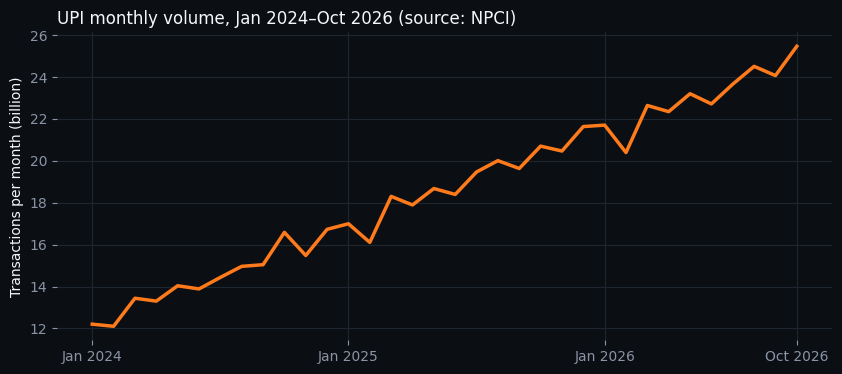

In [5]:
# CELL: data_plot
fig, ax = plt.subplots(figsize=(10, 4), dpi=100)
x = np.arange(N_MONTHS)
ax.plot(x, df.volume_mn / 1000, color=ACCENT, lw=2.5)
ax.set_ylabel("Transactions per month (billion)")
ticks = [i for i, m in enumerate(df.month) if m.endswith("-01") or i == N_MONTHS - 1]
ax.set_xticks(ticks, [fmt_month(df.month[i]) for i in ticks])
ax.grid(color=GRID); ax.set_title(f"UPI monthly volume, {DATA_RANGE} (source: NPCI)", color=FG, loc="left")
for s in ax.spines.values(): s.set_visible(False)
plt.show()

## 3 · Model: a ~3B open model on a free GPU

`Qwen/Qwen2.5-Coder-3B-Instruct` in fp16 needs about 6.5 GB of VRAM, so it fits a free T4 with room to spare.
Decoding is greedy (deterministic), so the score is reproducible on the same hardware and library versions.

In [6]:
# CELL: model_load
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
HAS_GPU = torch.cuda.is_available()
if not HAS_GPU:
    print("No GPU found → switching to", CPU_FALLBACK_MODEL_ID, "(slower; enable a T4 for the headline run)")
    MODEL_ID = CPU_FALLBACK_MODEL_ID
t0 = time.time()
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16 if HAS_GPU else torch.float32,
    device_map="auto" if HAS_GPU else None)
model.eval()

def llm_generate(messages, max_new_tokens=MAX_NEW_TOKENS):
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok([text], return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0][inputs.input_ids.shape[1]:], skip_special_tokens=True)

PARAMS_B = sum(p.numel() for p in model.parameters()) / 1e9
HARDWARE = torch.cuda.get_device_name(0) if HAS_GPU else "CPU"
print(f"Loaded {MODEL_ID} ({PARAMS_B:.2f}B params) on {HARDWARE} in {time.time() - t0:.0f}s")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-Coder-3B-Instruct (3.09B params) on Tesla T4 in 114s


In [7]:
# CELL: model_label
MODEL_LABEL = MODEL_ID.split("/")[-1]
_m = re.search(r"(\d+(?:\.\d+)?)B", MODEL_LABEL)
MODEL_SIZE = f"{_m.group(1)}B" if _m else f"{PARAMS_B:.1f}B"   # e.g. "3B", taken from the model name

## 4 · Method: text-to-SQL with guard-rails

1. The prompt contains the table schema, units, a short Hindi→column glossary, three sample rows and two worked
   examples (one English, one Hindi). None of the examples is in the evaluation set.
2. We extract the SQL from the model's reply and accept only **one read-only `SELECT`/`WITH` statement**. It runs on
   a read-only SQLite connection with an authorizer that blocks writes and a time limit.
3. If the SQL fails, the model sees the error once and may fix it (`SELF_CORRECT_RETRIES`).
4. The result is turned into a chart and a one-line answer by deterministic code, not the LLM, so the summary
   cannot invent numbers.

In [8]:
# CELL: text2sql
with sqlite3.connect(DB_PATH) as con:
    SCHEMA_DDL = con.execute("SELECT sql FROM sqlite_master WHERE name='upi_monthly'").fetchone()[0]
    SAMPLE = pd.read_sql("SELECT * FROM upi_monthly ORDER BY month DESC LIMIT 3", con)

SYSTEM_PROMPT = f"""You translate questions about India's UPI payments data into ONE SQLite query.
Questions may be in English or Hindi (Devanagari). Reply with a single SELECT statement inside ```sql ... ``` and nothing else.

Table schema:
{SCHEMA_DDL}

Notes:
- Data covers {FIRST} to {LAST}, one row per month. month is text 'YYYY-MM' (October 2026 -> '2026-10').
- fiscal_year is India's financial year April-March, e.g. April 2025-March 2026 = '2025-26'.
- volume_mn = number of transactions in millions (1 billion = 1000 million). value_cr = value in rupees crore.
  1 lakh crore = 100000 crore. Average transaction size in rupees = value_cr * 1e7 / (volume_mn * 1e6).
- banks_live may be NULL for some months.
- For "which month" questions return the month column. Return only the columns needed. Percentages as numbers like 12.5.
- Hindi glossary: महीना=month, साल/वर्ष=year, वित्त वर्ष=fiscal_year, लेनदेन की संख्या/वॉल्यूम=volume_mn,
  मूल्य=value_cr, बैंक=banks_live, कुल=SUM, औसत=AVG, सबसे ज़्यादा=highest, सबसे कम=lowest, पिछले महीने=previous month,
  जनवरी=01 फ़रवरी=02 मार्च=03 अप्रैल=04 मई=05 जून=06 जुलाई=07 अगस्त=08 सितंबर=09 अक्टूबर=10 नवंबर=11 दिसंबर=12.

Sample rows:
{SAMPLE.to_string(index=False)}"""

FEW_SHOT = [
    ("What was the UPI volume in June 2024?",
     "SELECT volume_mn FROM upi_monthly WHERE month = '2024-06';"),
    ("2024 में कुल UPI मूल्य कितने लाख करोड़ रुपये था?",
     "SELECT SUM(value_cr) / 100000.0 AS value_lakh_cr FROM upi_monthly WHERE year = 2024;"),
]

def build_messages(question):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    for q, s in FEW_SHOT:
        msgs += [{"role": "user", "content": q}, {"role": "assistant", "content": f"```sql\n{s}\n```"}]
    msgs.append({"role": "user", "content": question})
    return msgs

def extract_sql(text):
    m = re.search(r"```(?:sql|sqlite)?\s*(.*?)```", text, re.S | re.I)
    s = m.group(1) if m else text
    m2 = re.search(r"\b(WITH|SELECT)\b.*", s, re.S | re.I)
    s = (m2.group(0) if m2 else s).strip()
    s = s.split(";")[0].strip() if ";" in s and s.split(";", 1)[1].strip() == "" else s.rstrip(";").strip()
    return s

_ALLOWED = {sqlite3.SQLITE_SELECT, sqlite3.SQLITE_READ, sqlite3.SQLITE_FUNCTION}
def _authorizer(action, *args):
    return sqlite3.SQLITE_OK if action in _ALLOWED else sqlite3.SQLITE_DENY

def run_sql(sql):
    """Validate and execute one read-only query. Returns (columns, rows). Raises on any problem."""
    if not re.match(r"^\s*(SELECT|WITH)\b", sql, re.I):
        raise ValueError("Only SELECT/WITH queries are allowed")
    if ";" in sql.strip().rstrip(";"):
        raise ValueError("Only one statement is allowed")
    con = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)
    try:
        con.set_authorizer(_authorizer)
        deadline = time.time() + SQL_TIMEOUT_S
        con.set_progress_handler(lambda: 1 if time.time() > deadline else 0, 10000)
        cur = con.execute(sql)
        rows = cur.fetchmany(500)
        cols = [d[0] for d in cur.description]
        return cols, [tuple(r) for r in rows]
    finally:
        con.close()

def detect_lang(q):
    return "hi" if has_deva(q) else "en"

def ask(question, generate=None):
    """question → SQL → result. Returns a dict with everything we need for scoring, charts and the demo."""
    generate = generate or llm_generate
    msgs = build_messages(question)
    t0 = time.time(); attempts = 0; err = None; cols, rows, sql = [], [], ""
    while attempts <= SELF_CORRECT_RETRIES:
        attempts += 1
        reply = generate(msgs)
        sql = extract_sql(reply)
        try:
            cols, rows = run_sql(sql); err = None; break
        except Exception as e:
            err = f"{type(e).__name__}: {e}"
            msgs = msgs + [{"role": "assistant", "content": reply},
                           {"role": "user", "content": f"That query failed with: {err}\nReturn a corrected single SQLite SELECT in ```sql```."}]
    return {"question": question, "lang": detect_lang(question), "sql": sql, "ok": err is None, "error": err,
            "columns": cols, "rows": rows, "latency_s": time.time() - t0, "attempts": attempts}

In [9]:
# CELL: present
def fmt_in(x, decimals=2):
    """Indian digit grouping: 3152929.46 → 31,52,929.46"""
    if x is None: return "—"
    if isinstance(x, str): return x
    neg = x < 0; x = abs(float(x))
    s = f"{x:.{decimals}f}"; whole, _, frac = s.partition(".")
    if len(whole) > 3:
        head, tail = whole[:-3], whole[-3:]
        head = ",".join([head[max(i - 2, 0):i] for i in range(len(head), 0, -2)][::-1])
        whole = head + "," + tail
    return ("-" if neg else "") + whole + ("." + frac if frac else "")

def _is_num(v): return isinstance(v, (int, float)) and not isinstance(v, bool)

def answer_line(res):
    hi = res["lang"] == "hi"
    if not res["ok"]:
        return ("माफ़ कीजिए, इस सवाल का SQL नहीं चल पाया।" if hi else "Sorry, the generated SQL could not be run.")
    cols, rows = res["columns"], res["rows"]
    if not rows:
        return "कोई परिणाम नहीं मिला।" if hi else "No matching rows."
    if len(rows) == 1:
        parts = [f"{c} = {fmt_in(v) if _is_num(v) else v}" for c, v in zip(cols, rows[0])]
        return ("उत्तर: " if hi else "Answer: ") + ", ".join(parts)
    num_i = [i for i in range(len(cols)) if all(_is_num(r[i]) or r[i] is None for r in rows)]
    lab_i = [i for i in range(len(cols)) if i not in num_i] or [0]
    if num_i:
        j, k = num_i[-1], lab_i[0]
        best = max((r for r in rows if r[j] is not None), key=lambda r: r[j])
        if hi:
            return f"{len(rows)} पंक्तियाँ · सबसे ज़्यादा {cols[j]}: {best[k]} ({fmt_in(best[j])})"
        return f"{len(rows)} rows · highest {cols[j]}: {best[k]} ({fmt_in(best[j])})"
    return f"{len(rows)} पंक्तियाँ" if hi else f"{len(rows)} rows"

def chart_spec(res):
    """Pick (labels, values, value_col) for a bar chart, or None if the result is not chartable."""
    cols, rows = res["columns"], res["rows"]
    if not res["ok"] or len(rows) < 2 or len(cols) < 2: return None
    num_i = [i for i in range(len(cols)) if all(_is_num(r[i]) or r[i] is None for r in rows)]
    lab_i = [i for i in range(len(cols)) if i not in num_i]
    if not num_i: return None
    j = num_i[-1]
    k = lab_i[0] if lab_i else [i for i in range(len(cols)) if i != j][0]
    return [str(r[k]) for r in rows], [float(r[j] or 0) for r in rows], cols[j]

def result_figure(res):
    """matplotlib figure for the demo: a bar chart for multi-row results, a big number card for scalars."""
    fig, ax = plt.subplots(figsize=(8, 4), dpi=100)
    spec = chart_spec(res)
    if spec:
        labels, vals, vcol = spec
        ax.bar(range(len(vals)), vals, color=ACCENT)
        step = max(1, len(labels) // 12)
        ax.set_xticks(range(0, len(labels), step), labels[::step], rotation=45, ha="right")
        ax.set_ylabel(vcol); ax.grid(axis="y", color=GRID)
        for s in ax.spines.values(): s.set_visible(False)
    else:
        ax.axis("off")
        if res["ok"] and res["rows"]:
            v = res["rows"][0][-1]
            ax.text(0.5, 0.55, fmt_in(v) if _is_num(v) else str(v), ha="center", va="center", fontsize=40, color=ACCENT, weight="bold")
            ax.text(0.5, 0.2, res["columns"][-1], ha="center", fontsize=14, color=MUTED)
        else:
            ax.text(0.5, 0.5, "no result", ha="center", color=MUTED, fontsize=20)
    fig.tight_layout()
    return fig

## 5 · Evaluation: 25 questions (12 English, 13 Hindi) with gold SQL

**Scoring (execution accuracy).** The model's query must return the same number of rows as the gold query, and every
gold column must match some column of the model's result as a multiset of values. Numbers may differ by 0.1 %, which
allows for rounding. Extra columns are allowed, and row order is ignored. Units are part of the question: if a
question asks for ₹ crore and the model returns lakh crore, it is marked wrong.

In [10]:
# CELL: eval_set
EVAL = [
 # ---- English ----
 ("en", "How many UPI transactions, in millions, were made in October 2026?",
  "SELECT volume_mn FROM upi_monthly WHERE month = '2026-10'"),
 ("en", "What was the total UPI transaction value in calendar year 2025, in rupees crore?",
  "SELECT SUM(value_cr) FROM upi_monthly WHERE year = 2025"),
 ("en", "Which month had the highest UPI transaction volume?",
  "SELECT month FROM upi_monthly ORDER BY volume_mn DESC LIMIT 1"),
 ("en", "How many banks were live on UPI in March 2026?",
  "SELECT banks_live FROM upi_monthly WHERE month = '2026-03'"),
 ("en", "What was the average UPI transaction size in rupees in October 2026?",
  "SELECT value_cr * 1e7 / (volume_mn * 1e6) FROM upi_monthly WHERE month = '2026-10'"),
 ("en", "Show the monthly UPI volume for each month of 2025.",
  "SELECT month, volume_mn FROM upi_monthly WHERE year = 2025 ORDER BY month"),
 ("en", "In how many months did UPI volume exceed 20,000 million transactions?",
  "SELECT COUNT(*) FROM upi_monthly WHERE volume_mn > 20000"),
 ("en", "What was the total UPI volume in fiscal year 2025-26, in millions?",
  "SELECT SUM(volume_mn) FROM upi_monthly WHERE fiscal_year = '2025-26'"),
 ("en", "By what percentage did UPI volume grow from October 2025 to October 2026?",
  "SELECT (b.volume_mn - a.volume_mn) * 100.0 / a.volume_mn FROM upi_monthly a, upi_monthly b WHERE a.month = '2025-10' AND b.month = '2026-10'"),
 ("en", "Which month of 2024 had the lowest UPI transaction value?",
  "SELECT month FROM upi_monthly WHERE year = 2024 ORDER BY value_cr ASC LIMIT 1"),
 ("en", "Compare the total UPI volume in millions for each calendar year.",
  "SELECT year, SUM(volume_mn) FROM upi_monthly GROUP BY year ORDER BY year"),
 ("en", "What was the UPI transaction value in December 2025, in lakh crore rupees?",
  "SELECT value_cr / 100000.0 FROM upi_monthly WHERE month = '2025-12'"),
 # ---- Hindi ----
 ("hi", "अक्टूबर 2026 में UPI लेनदेन का कुल मूल्य कितने करोड़ रुपये था?",
  "SELECT value_cr FROM upi_monthly WHERE month = '2026-10'"),
 ("hi", "2025 में कुल कितने मिलियन UPI लेनदेन हुए?",
  "SELECT SUM(volume_mn) FROM upi_monthly WHERE year = 2025"),
 ("hi", "किस महीने में UPI लेनदेन का मूल्य सबसे ज़्यादा था?",
  "SELECT month FROM upi_monthly ORDER BY value_cr DESC LIMIT 1"),
 ("hi", "जनवरी 2024 में कितने बैंक UPI पर लाइव थे?",
  "SELECT banks_live FROM upi_monthly WHERE month = '2024-01'"),
 ("hi", "2026 के हर महीने का UPI वॉल्यूम (मिलियन में) दिखाइए।",
  "SELECT month, volume_mn FROM upi_monthly WHERE year = 2026 ORDER BY month"),
 ("hi", "वित्त वर्ष 2024-25 में UPI लेनदेन का कुल मूल्य कितने करोड़ रुपये था?",
  "SELECT SUM(value_cr) FROM upi_monthly WHERE fiscal_year = '2024-25'"),
 ("hi", "कितने महीनों में UPI लेनदेन का मूल्य 25 लाख करोड़ रुपये से ज़्यादा था?",
  "SELECT COUNT(*) FROM upi_monthly WHERE value_cr > 2500000"),
 ("hi", "मार्च 2025 में एक UPI लेनदेन का औसत आकार कितने रुपये था?",
  "SELECT value_cr * 1e7 / (volume_mn * 1e6) FROM upi_monthly WHERE month = '2025-03'"),
 ("hi", "2024 में औसत मासिक UPI वॉल्यूम कितने मिलियन था?",
  "SELECT AVG(volume_mn) FROM upi_monthly WHERE year = 2024"),
 ("hi", "फ़रवरी 2026 में UPI वॉल्यूम पिछले महीने की तुलना में कितने प्रतिशत बदला?",
  "SELECT (b.volume_mn - a.volume_mn) * 100.0 / a.volume_mn FROM upi_monthly a, upi_monthly b WHERE a.month = '2026-01' AND b.month = '2026-02'"),
 ("hi", "हर वित्त वर्ष में UPI लेनदेन का कुल मूल्य (करोड़ रुपये में) दिखाइए।",
  "SELECT fiscal_year, SUM(value_cr) FROM upi_monthly GROUP BY fiscal_year ORDER BY fiscal_year"),
 ("hi", "जनवरी 2024 से अक्टूबर 2026 के बीच UPI पर लाइव बैंकों की संख्या कितनी बढ़ी?",
  "SELECT b.banks_live - a.banks_live FROM upi_monthly a, upi_monthly b WHERE a.month = '2024-01' AND b.month = '2026-10'"),
 ("hi", "किस महीने में सबसे कम UPI लेनदेन हुए?",
  "SELECT month FROM upi_monthly ORDER BY volume_mn ASC LIMIT 1"),
]
assert len(EVAL) == 25
# Gold SQL must run and return something on the loaded data.
GOLD = []
for lang, q, g in EVAL:
    cols, rows = run_sql(g)
    assert rows and all(v is not None for r in rows for v in r), f"gold query empty/NULL: {q}"
    GOLD.append((cols, rows))
print(f"{len(EVAL)} questions: {sum(l == 'en' for l, _, _ in EVAL)} English, {sum(l == 'hi' for l, _, _ in EVAL)} Hindi; all gold SQL OK")

25 questions: 12 English, 13 Hindi; all gold SQL OK


In [11]:
# CELL: scoring
def _norm(v):
    if v is None: return None
    if _is_num(v): return float(v)
    s = str(v).strip()
    try: return float(s.replace(",", ""))
    except ValueError: return s.lower()

def _key(v): return (0, v, "") if isinstance(v, float) else ((2, 0, "") if v is None else (1, 0, str(v)))

def _col_equal(g, p):
    g, p = sorted(map(_norm, g), key=_key), sorted(map(_norm, p), key=_key)
    for a, b in zip(g, p):
        if isinstance(a, float) and isinstance(b, float):
            if not math.isclose(a, b, rel_tol=NUM_REL_TOL, abs_tol=0.01): return False
        elif a != b:
            return False
    return True

def results_match(gold_rows, pred_rows):
    if len(gold_rows) != len(pred_rows): return False
    if not gold_rows: return True
    gcols, pcols = list(zip(*gold_rows)), list(zip(*pred_rows))
    used = set()
    for gc in gcols:
        hit = next((i for i, pc in enumerate(pcols) if i not in used and _col_equal(gc, pc)), None)
        if hit is None: return False
        used.add(hit)
    return True

# Self-test of the scorer.
assert results_match([(1.0,)], [(1.0004,)]) and not results_match([(1.0,)], [(1.1,)])
assert results_match([("2026-10",)], [("2026-10", 25466.7)]) and not results_match([(1,), (2,)], [(1,)])

In [12]:
# CELL: run_eval
EVAL_RESULTS = []
for i, ((lang, q, gold_sql), (gcols, grows)) in enumerate(zip(EVAL, GOLD), 1):
    r = ask(q)
    r["gold_sql"] = gold_sql
    r["correct"] = bool(r["ok"] and results_match(grows, r["rows"]))
    EVAL_RESULTS.append(r)
    print(f"{i:2d} [{lang}] {'✓' if r['correct'] else '✗'} {r['latency_s']:.1f}s  {q[:70]}")
    if not r["correct"]:
        print("     model:", r["sql"][:160].replace("\n", " "), "|", r["error"] or r["rows"][:3])

 1 [en] ✓ 3.3s  How many UPI transactions, in millions, were made in October 2026?
 2 [en] ✗ 1.4s  What was the total UPI transaction value in calendar year 2025, in rup
     model: SELECT SUM(value_cr) FROM upi_monthly WHERE fiscal_year = '2025-26' | [(31423249.71,)]
 3 [en] ✓ 1.2s  Which month had the highest UPI transaction volume?
 4 [en] ✓ 1.6s  How many banks were live on UPI in March 2026?
 5 [en] ✓ 2.4s  What was the average UPI transaction size in rupees in October 2026?
 6 [en] ✓ 1.3s  Show the monthly UPI volume for each month of 2025.
 7 [en] ✓ 1.3s  In how many months did UPI volume exceed 20,000 million transactions?
 8 [en] ✓ 1.4s  What was the total UPI volume in fiscal year 2025-26, in millions?
 9 [en] ✓ 3.7s  By what percentage did UPI volume grow from October 2025 to October 20
10 [en] ✓ 1.6s  Which month of 2024 had the lowest UPI transaction value?
11 [en] ✓ 1.8s  Compare the total UPI volume in millions for each calendar year.
12 [en] ✓ 2.0s  What was the UPI tra

## 6 · Results: the headline number

A 3B-parameter open model answers 16/25 questions about India's UPI data correctly — in Hindi and English — on a free GPU.
Qwen2.5-Coder-3B-Instruct writes SQL over 34 months of NPCI UPI statistics (Jan 2024–Oct 2026); English 11/12, Hindi 5/13; median 1.6s per question on Tesla T4.


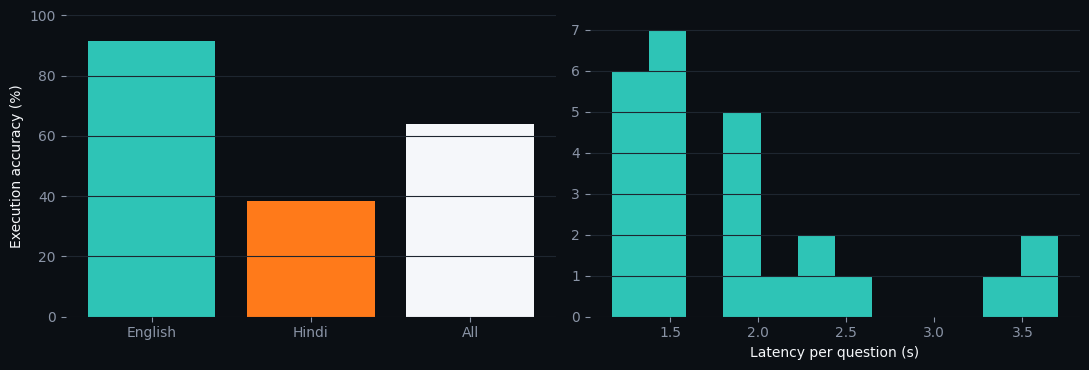

,lang,correct,latency_s,attempts,question
0,en,True,3.30,1,"How many UPI transactions, in millions, were m..."
1,en,False,1.41,1,What was the total UPI transaction value in ca...
2,en,True,1.17,1,Which month had the highest UPI transaction vo...
3,en,True,1.56,1,How many banks were live on UPI in March 2026?
4,en,True,2.42,1,What was the average UPI transaction size in r...
5,en,True,1.30,1,Show the monthly UPI volume for each month of ...
6,en,True,1.26,1,"In how many months did UPI volume exceed 20,00..."
7,en,True,1.44,1,What was the total UPI volume in fiscal year 2...
8,en,True,3.70,1,By what percentage did UPI volume grow from Oc...
9,en,True,1.59,1,Which month of 2024 had the lowest UPI transac...


In [13]:
# CELL: results
res_df = pd.DataFrame([{"lang": r["lang"], "question": r["question"], "correct": r["correct"],
                        "latency_s": round(r["latency_s"], 2), "attempts": r["attempts"],
                        "model_sql": r["sql"], "gold_sql": r["gold_sql"], "error": r["error"]} for r in EVAL_RESULTS])
res_df.to_csv("ft04_eval_results.csv", index=False)
N_TOTAL = len(res_df); N_CORRECT = int(res_df.correct.sum())
EN_TOTAL = int((res_df.lang == "en").sum()); EN_CORRECT = int(res_df[res_df.lang == "en"].correct.sum())
HI_TOTAL = int((res_df.lang == "hi").sum()); HI_CORRECT = int(res_df[res_df.lang == "hi"].correct.sum())
LAT_MEDIAN = float(res_df.latency_s.median()); LAT_P90 = float(res_df.latency_s.quantile(0.9))
LAT_TOTAL = float(res_df.latency_s.sum())
HEADLINE = (f"A {MODEL_SIZE}-parameter open model answers {N_CORRECT}/{N_TOTAL} questions about India's UPI data "
            f"correctly — in Hindi and English — on a free GPU.")
HOW = (f"{MODEL_LABEL} writes SQL over {N_MONTHS} months of NPCI UPI statistics ({DATA_RANGE}); "
       f"English {EN_CORRECT}/{EN_TOTAL}, Hindi {HI_CORRECT}/{HI_TOTAL}; median {LAT_MEDIAN:.1f}s per question on {HARDWARE}.")
print(HEADLINE); print(HOW)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), dpi=100)
axes[0].bar(["English", "Hindi", "All"], [EN_CORRECT / EN_TOTAL * 100, HI_CORRECT / HI_TOTAL * 100, N_CORRECT / N_TOTAL * 100],
            color=[TEAL, ACCENT, FG])
axes[0].set_ylim(0, 100); axes[0].set_ylabel("Execution accuracy (%)")
axes[1].hist(res_df.latency_s, bins=12, color=TEAL); axes[1].set_xlabel("Latency per question (s)")
for ax in axes:
    ax.grid(axis="y", color=GRID)
    for s in ax.spines.values(): s.set_visible(False)
fig.tight_layout(); fig.savefig("ft04_results.png", facecolor=BG); plt.show()
res_df[["lang", "correct", "latency_s", "attempts", "question"]]

### Optional: compare with a frontier API model (Claude)
This cell is skipped unless `ANTHROPIC_API_KEY` is set, either as an environment variable or as a Colab secret.
It sends the same prompt to the same scorer. Calls are paid. The free model above is the headline result.

In [14]:
# CELL: claude_optional
def _get_key():
    k = os.environ.get("ANTHROPIC_API_KEY")
    if not k and IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("ANTHROPIC_API_KEY")
        except Exception:
            k = None
    return k

CLAUDE_SUMMARY = None
_key = _get_key()
if not _key:
    print("ANTHROPIC_API_KEY not set → skipping the optional Claude comparison.")
else:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "anthropic"], check=False)
    import anthropic
    client = anthropic.Anthropic(api_key=_key)
    def claude_generate(messages, max_new_tokens=1024):
        sys_msg = messages[0]["content"]
        out = client.messages.create(model=CLAUDE_MODEL, max_tokens=max_new_tokens, system=sys_msg, messages=messages[1:])
        return "".join(b.text for b in out.content if getattr(b, "type", "") == "text")
    c_ok, c_lat = [], []
    for (lang, q, g), (gcols, grows) in zip(EVAL, GOLD):
        r = ask(q, generate=claude_generate)
        c_ok.append(bool(r["ok"] and results_match(grows, r["rows"]))); c_lat.append(r["latency_s"])
    CLAUDE_SUMMARY = f"{CLAUDE_MODEL}: {sum(c_ok)}/{len(c_ok)} correct, median {statistics.median(c_lat):.1f}s (API)"
    print(CLAUDE_SUMMARY, "| vs", f"{MODEL_LABEL}: {N_CORRECT}/{N_TOTAL}")

ANTHROPIC_API_KEY not set → skipping the optional Claude comparison.


## 7 · Interactive demo
Type a question in English or Hindi. You get the generated SQL, the answer and a chart. The cell does not block
"Run all". Open the public `gradio.live` link it prints.

In [15]:
# CELL: gradio
import gradio as gr

def gr_answer(question):
    question = (question or "").strip()
    if not question:
        return "", "Type a question first.", None, None
    r = ask(question)
    table = pd.DataFrame(r["rows"], columns=r["columns"]) if r["ok"] else pd.DataFrame({"error": [r["error"]]})
    md_ans = f"**{answer_line(r)}**  \n<sub>{r['latency_s']:.1f}s · {MODEL_LABEL} · data: NPCI UPI statistics {DATA_RANGE}</sub>"
    fig = result_figure(r); plt.close(fig)
    return r["sql"], md_ans, fig, table

with gr.Blocks(title="23N Field Test #04 · Ask India's payments data") as demo:
    gr.Markdown(f"## Ask India's UPI data, in Hindi or English\n{MODEL_LABEL} runs on this notebook's GPU and turns your "
                f"question into SQL over {N_MONTHS} months of NPCI UPI statistics ({DATA_RANGE}). "
                "Independent study on public data · 23N AI Labs.")
    q = gr.Textbox(label="Your question / आपका सवाल", placeholder="किस महीने में UPI लेनदेन सबसे ज़्यादा हुए?")
    btn = gr.Button("Ask", variant="primary")
    sql_out = gr.Code(label="Generated SQL", language="sql")
    ans_out = gr.Markdown()
    plot_out = gr.Plot(label="Chart")
    tbl_out = gr.Dataframe(label="Result rows")
    gr.Examples(["2026 में हर महीने कितने करोड़ रुपये के UPI लेनदेन हुए?",
                 "What was the average UPI transaction size in rupees in each month of 2026?",
                 "वित्त वर्ष 2025-26 में कुल कितने मिलियन UPI लेनदेन हुए?"], inputs=q)
    btn.click(gr_answer, q, [sql_out, ans_out, plot_out, tbl_out])
    q.submit(gr_answer, q, [sql_out, ans_out, plot_out, tbl_out])

demo.launch(share=True, prevent_thread_lock=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e2d8add43578863ad4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 8 · Video render (1080×1080, 30 fps, ~58 s, H.264) + cover (1080×1350)
Every chart and number in the video comes from the run above. The two demo questions are the first correct
multi-row Hindi and English answers, falling back to any answer if none qualify. The scorecard shows all 25
results, wrong ones included.

In [16]:
# CELL: video_lib
VIDEO_PATH, COVER_PATH = f"ft{FT_NUM}_video.mp4", f"ft{FT_NUM}_cover.png"
FPS, W_PX = 30, 1080
_VIRAMA = "्"

def grapheme_clusters(s):
    """Rough Devanagari-aware clusters so the typing animation never shows a dangling matra or half-conjunct."""
    out = []
    for ch in s:
        if out and (unicodedata.category(ch) in ("Mn", "Mc") or out[-1].endswith(_VIRAMA) or ch in "‌‍"):
            out[-1] += ch
        else:
            out.append(ch)
    return out

def _ease(p): p = min(max(p, 0.0), 1.0); return 1 - (1 - p) ** 3
def _prog(t, a, b): return min(max((t - a) / (b - a), 0.0), 1.0)

def pick_demo(results, lang):
    pool = [r for r in results if r["lang"] == lang]
    for cond in (lambda r: r["correct"] and chart_spec(r), lambda r: r["correct"], lambda r: r["ok"], lambda r: True):
        hits = [r for r in pool if cond(r)]
        if hits: return hits[0]
    return None

def _new_fig(h_px=W_PX):
    fig = plt.figure(figsize=(W_PX / 100, h_px / 100), dpi=100)
    fig.patch.set_facecolor(BG)
    return fig

def _caption(fig, text, H=W_PX):
    fig.text(0.5, 40 / H, text, ha="center", va="bottom", fontsize=17, color=FG,
             bbox=dict(boxstyle="round,pad=0.5", fc="#000000", ec="none", alpha=0.65))

def _brand(fig):
    fig.text(0.04, 0.965, f"23N FIELD TESTS · #{FT_NUM}", fontsize=13, color=ACCENT, weight="bold", va="top")

def _draw_bars(fig, rect, labels, vals, grow, highlight=None, ylabel=""):
    ax = fig.add_axes(rect); ax.set_facecolor(BG)
    n = len(vals); vmax = max(vals) if vals else 1
    heights = [v * _ease(grow * 1.6 - i / max(n, 1) * 0.6) for i, v in enumerate(vals)]
    colors = [ACCENT if (highlight is not None and i == highlight) else TEAL for i in range(n)]
    ax.bar(range(n), heights, color=colors, width=0.75)
    ax.set_ylim(0, vmax * 1.15); ax.set_xlim(-0.7, n - 0.3)
    step = max(1, int(math.ceil(n / 8)))
    ax.set_xticks(range(0, n, step), [labels[i] for i in range(0, n, step)], fontsize=13, color=MUTED)
    ax.tick_params(axis="y", labelsize=12, colors=MUTED); ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
    ax.set_ylabel(ylabel, fontsize=13, color=MUTED)
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: fmt_in(v, 0)))
    for s in ax.spines.values(): s.set_visible(False)
    return ax

def _question_block(fig, r, t, t0, t_type, t_sql, t_chart, t_ans, tag):
    """One question sequence: typing → SQL → chart → answer."""
    fig.text(0.06, 0.90, tag, fontsize=18, color=MUTED, va="top")
    cl = grapheme_clusters(r["question"])
    k = int(round(len(cl) * _prog(t, t0, t_type)))
    typed = "".join(cl[:k]) + ("|" if (t < t_type or int(t * 2) % 2 == 0) and t < t_sql else "")
    put_text_img(fig, typed or "|", 0.06, 0.86, 40, FG, bold=True, max_width=W_PX * 0.88)
    if t >= t_type:
        sql_lines = textwrap.wrap(re.sub(r"\s+", " ", r["sql"]), 58)[:5]
        sql_txt = "\n".join(sql_lines)
        n = int(len(sql_txt) * _prog(t, t_type, t_sql))
        fig.text(0.06, 0.71, "SQL written by the model", fontsize=14, color=MUTED, va="top")
        fig.text(0.06, 0.68, sql_txt[:n], fontsize=17, color=TEAL, va="top", family="DejaVu Sans Mono", linespacing=1.4)
    if t >= t_sql:
        spec = chart_spec(r)
        g = _prog(t, t_sql, t_chart)
        if spec:
            labels, vals, vcol = spec
            short = [l[2:] if re.match(r"^\d{4}-\d{2}$", l) else l for l in labels]   # '2026-03' → '26-03'
            _draw_bars(fig, [0.11, 0.24, 0.83, 0.26], short, vals, g, highlight=int(np.argmax(vals)), ylabel=vcol)
        elif r["ok"] and r["rows"]:
            v = r["rows"][0][-1]
            shown = fmt_in(v * _ease(g)) if _is_num(v) else str(v)
            fig.text(0.5, 0.40, shown, ha="center", va="center", fontsize=72, color=ACCENT, weight="bold")
            fig.text(0.5, 0.31, str(r["columns"][-1])[:40], ha="center", fontsize=18, color=MUTED)
    if t >= t_chart:
        a = _prog(t, t_chart, t_chart + 0.6)
        put_text_img(fig, answer_line(r), 0.06, 0.19, 28, FG, bold=True, max_width=W_PX * 0.88, alpha=a)
        badge = ("✓ matches the reference answer" if r["correct"] else "✗ does not match the reference answer")
        fig.text(0.06, 0.125, badge, fontsize=17, color=TEAL if r["correct"] else ACCENT, alpha=a, va="top")

def make_frame_drawer(ctx):
    rq_hi, rq_en = ctx["demo_hi"], ctx["demo_en"]
    def draw(fig, t):
        _brand(fig)
        if t < 5:                                                    # hook
            a = _prog(t, 0, 0.6)
            fig.text(0.07, 0.66, "Ask India's payments\ndata a question —", fontsize=58, color=FG, weight="bold",
                     va="top", alpha=a, linespacing=1.15)
            if t > 1.4:
                b = _prog(t, 1.4, 2.0)
                fig.text(0.07, 0.42, "in Hindi.", fontsize=64, color=ACCENT, weight="bold", va="top", alpha=b)
                put_text_img(fig, "हिंदी में पूछिए।", 0.07, 0.30, 64, TEAL, bold=True, alpha=b)
            _caption(fig, "Can a small open AI model answer it correctly, for free?")
        elif t < 9:                                                  # the data
            fig.text(0.06, 0.90, "The data", fontsize=18, color=MUTED, va="top")
            fig.text(0.06, 0.86, "UPI transactions per month (billion)", fontsize=34, color=FG, weight="bold", va="top")
            ax = fig.add_axes([0.1, 0.2, 0.84, 0.55]); ax.set_facecolor(BG)
            y = ctx["volume_bn"]; n = len(y); k = max(2, int(n * _ease(_prog(t, 5.2, 8.0))))
            ax.plot(range(k), y[:k], color=ACCENT, lw=4); ax.set_xlim(0, n - 1); ax.set_ylim(0, max(y) * 1.12)
            ax.set_xticks(ctx["tick_pos"], ctx["tick_lab"], fontsize=14, color=MUTED)
            ax.tick_params(axis="y", labelsize=14, colors=MUTED); ax.grid(color=GRID)
            for s in ax.spines.values(): s.set_visible(False)
            if k == n:
                ax.annotate(f"{y[-1]:.1f} bn", (n - 1, y[-1]), xytext=(-110, 10), textcoords="offset points",
                            fontsize=20, color=ACCENT, weight="bold")
            _caption(fig, f"{ctx['n_months']} months of official UPI statistics (NPCI), {ctx['range']}")
        elif t < 25:                                                 # Hindi question
            _question_block(fig, rq_hi, t, 9.3, 13.0, 15.5, 21.0, 25, "Question · हिंदी")
            _caption(fig, f"{ctx['model']} turns the Hindi question into SQL")
        elif t < 40:                                                 # English question
            _question_block(fig, rq_en, t, 25.3, 27.8, 30.0, 35.5, 40, "Question · English")
            _caption(fig, "The SQL runs on the real table. The chart is drawn from the result")
        elif t < 52:                                                 # headline + scorecard
            a = _prog(t, 40, 40.8)
            fig.text(0.07, 0.86, f"{ctx['n_correct']}/{ctx['n_total']}", fontsize=170, color=ACCENT, weight="bold",
                     va="top", alpha=a)
            fig.text(0.07, 0.63, f"questions answered correctly by a\n{ctx['size']}-parameter open model, on a free GPU",
                     fontsize=30, color=FG, va="top", alpha=a, linespacing=1.25)
            nshow = int(round(len(ctx["marks"]) * _prog(t, 41.5, 46)))
            _col = {"en": 0, "hi": 0}
            for i, (lang, ok) in enumerate(ctx["marks"]):
                row = 0 if lang == "en" else 1; c = _col[lang]; _col[lang] += 1
                if i >= nshow: continue
                cx, cy = 0.07 + c * 0.067, 0.42 - row * 0.085
                fig.patches.append(matplotlib.patches.FancyBboxPatch((cx, cy), 0.052, 0.058, boxstyle="round,pad=0.004",
                                   transform=fig.transFigure, fc=TEAL if ok else "#3A4350", ec="none"))
                fig.text(cx + 0.026, cy + 0.029, lang.upper(), ha="center", va="center", fontsize=13,
                         color=BG if ok else MUTED, weight="bold")
            if t > 46:
                fig.text(0.07, 0.22, f"Hindi {ctx['hi']} · English {ctx['en']} · median {ctx['lat']:.1f}s per question",
                         fontsize=22, color=FG, va="top", alpha=_prog(t, 46, 46.6))
                fig.text(0.07, 0.17, f"How: {ctx['model']} writes SQL, validated and run on SQLite",
                         fontsize=18, color=MUTED, va="top", alpha=_prog(t, 46, 46.6))
            _caption(fig, "Scored against hand-written reference SQL. Teal = correct")
        else:                                                        # end card
            a = _prog(t, 52, 52.6)
            fig.text(0.5, 0.60, "23N AI Labs", ha="center", fontsize=72, color=FG, weight="bold", alpha=a)
            fig.text(0.5, 0.52, f"Field Test #{FT_NUM} · Open notebook in comments", ha="center", fontsize=28,
                     color=ACCENT, alpha=a)
            fig.text(0.5, 0.44, "23nlabs.com", ha="center", fontsize=30, color=TEAL, alpha=a, weight="bold")
            fig.text(0.5, 0.12, "Independent study on public data. Not affiliated with NPCI or RBI.", ha="center",
                     fontsize=15, color=MUTED, alpha=a)
    return draw

def _frame_key(t):
    """Frames that would look identical share a key, so they are rendered once."""
    if t < 5:   return ("hook", min(round(t, 1), 2.1), int(t > 1.4))
    if t < 9:   return ("data", min(round(t * 15) / 15, 8.1))
    if t < 40:  return ("q", round(t * 30) / 30)
    if t < 52:  return ("score", min(round(t * 30) / 30, 46.7))
    return ("end", min(round(t, 1), 52.7))

def render_video(ctx, path=VIDEO_PATH, duration=58.0, fps=FPS):
    draw = make_frame_drawer(ctx)
    cmd = ["ffmpeg", "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "rgba", "-s", f"{W_PX}x{W_PX}",
           "-r", str(fps), "-i", "-", "-c:v", "libx264", "-preset", "veryfast", "-pix_fmt", "yuv420p",
           "-movflags", "+faststart", path]
    proc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
    fig = _new_fig(); cache_key, cache_buf = None, None
    t_start = time.time(); n = int(duration * fps)
    for f in range(n):
        t = f / fps; key = _frame_key(t)
        if key != cache_key:
            fig.clf(); fig.patch.set_facecolor(BG); draw(fig, t); fig.canvas.draw()
            cache_buf = bytes(fig.canvas.buffer_rgba()); cache_key = key
        proc.stdin.write(cache_buf)
    proc.stdin.close(); proc.wait(); plt.close(fig)
    print(f"Rendered {path}: {n} frames in {time.time() - t_start:.0f}s")
    return path

def render_cover(ctx, path=COVER_PATH):
    H = 1350
    fig = _new_fig(H)
    fig.text(0.06, 0.955, f"23N FIELD TESTS · #{FT_NUM}", fontsize=15, color=ACCENT, weight="bold", va="top")
    fig.text(0.06, 0.915, "Ask India's payments data\na question, in Hindi.", fontsize=46, color=FG, weight="bold",
             va="top", linespacing=1.15)
    fig.text(0.06, 0.76, f"{ctx['n_correct']}/{ctx['n_total']}", fontsize=150, color=ACCENT, weight="bold", va="top")
    fig.text(0.06, 0.60, f"questions answered correctly by a {ctx['size']} open model\non a free GPU · Hindi {ctx['hi']} · English {ctx['en']}",
             fontsize=24, color=FG, va="top", linespacing=1.3)
    put_text_img(fig, "“" + ctx["demo_hi"]["question"] + "”", 0.06, 0.505, 32, TEAL, bold=True, max_width=W_PX * 0.88)
    spec = chart_spec(ctx["demo_hi"])
    if spec:
        labels, vals, vcol = spec
        short = [l[2:] if re.match(r"^\d{4}-\d{2}$", l) else l for l in labels]
        _draw_bars(fig, [0.11, 0.13, 0.83, 0.26], short, vals, 1.0, highlight=int(np.argmax(vals)), ylabel=vcol)
    else:
        ax = fig.add_axes([0.1, 0.13, 0.84, 0.26]); ax.plot(ctx["volume_bn"], color=ACCENT, lw=4); ax.axis("off")
    fig.text(0.06, 0.045, "23N AI Labs · 23nlabs.com · data: NPCI UPI statistics · independent study", fontsize=15, color=MUTED)
    fig.savefig(path, dpi=100, facecolor=BG); plt.close(fig)
    return path

def build_video_ctx():
    vol_bn = (df.volume_mn / 1000).tolist()
    tick_pos = [i for i, m in enumerate(df.month) if m.endswith("-01")]
    return {"demo_hi": pick_demo(EVAL_RESULTS, "hi"), "demo_en": pick_demo(EVAL_RESULTS, "en"),
            "volume_bn": vol_bn, "tick_pos": tick_pos, "tick_lab": [df.month[i][:4] for i in tick_pos],
            "n_months": N_MONTHS, "range": DATA_RANGE, "model": MODEL_LABEL, "size": MODEL_SIZE,
            "n_correct": N_CORRECT, "n_total": N_TOTAL, "hi": f"{HI_CORRECT}/{HI_TOTAL}", "en": f"{EN_CORRECT}/{EN_TOTAL}",
            "lat": LAT_MEDIAN, "marks": [(r["lang"], r["correct"]) for r in EVAL_RESULTS]}

In [17]:
# CELL: video_render
VCTX = build_video_ctx()
render_video(VCTX)
render_cover(VCTX)
_probe = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries",
                         "stream=width,height,r_frame_rate,codec_name:format=duration", "-of", "json", VIDEO_PATH],
                        capture_output=True, text=True)
print(_probe.stdout)
try:
    from google.colab import files
    files.download(VIDEO_PATH); files.download(COVER_PATH)
except Exception:
    print("Not on Colab: video and cover saved in the working directory.")

/tmp/ipykernel_3038/3874961097.py:167: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.clf(); fig.patch.set_facecolor(BG); draw(fig, t); fig.canvas.draw()
/tmp/ipykernel_3038/3874961097.py:167: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.clf(); fig.patch.set_facecolor(BG); draw(fig, t); fig.canvas.draw()
/tmp/ipykernel_3038/3874961097.py:167: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.clf(); fig.patch.set_facecolor(BG); draw(fig, t); fig.canvas.draw()
/tmp/ipykernel_3038/3874961097.py:167: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.clf(); fig.patch.set_facecolor(BG); draw(fig, t); fig.canvas.draw()
/tmp/ipykernel_3038/3874961097.py:167: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.clf(); fig.patch.set_facecolor(BG); draw(fig, t); fig.canvas.draw()
/tmp/ipykernel_3038/3874961097.py:167: UserWarning: Matplotlib currently do

Rendered ft04_video.mp4: 1740 frames in 92s
{
    "programs": [

    ],
    "streams": [
        {
            "codec_name": "h264",
            "width": 1080,
            "height": 1080,
            "r_frame_rate": "30/1"
        }
    ],
    "format": {
        "duration": "58.000000"
    }
}



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9 · Post text (ready to paste)

In [18]:
# CELL: post_text
POST_LINKEDIN_TEMPLATE = """Can a free AI model correctly answer a question about India's payments data asked in Hindi?

23N Field Test #04: {headline}

How we tested it:
• Data: {n_months} months of official NPCI UPI statistics ({data_range})
• Model: {model_name}, open weights, on a free Colab GPU
• Method: the model writes SQL, we validate it and run it on the real table, and the result becomes a chart plus a one-line answer
• Score: 25 questions with hand-written reference SQL. English {en_correct}/{en_total}, Hindi {hi_correct}/{hi_total}. Median {median_latency}s per question

Example: "{example_q_hi}"
→ {example_answer}

Why it matters: departments, PSUs and banks sit on tabular data. A small model on cheap hardware that answers in the user's own language could open that data to far more people, as long as every answer shows its SQL so someone can check it.

Limits: one table, 25 questions, our own test set. Read it as a capability probe, not a benchmark.

Notebook in the comments. Try your own questions.

Independent study on public data. Not affiliated with NPCI or RBI.
#23NFieldTests #UPI #AI #Hindi
"""
POST_X_TEMPLATE = """Asked India's UPI data 25 questions in Hindi and English. A {model_size} open model on a free GPU wrote the SQL and got {n_correct}/{n_total} right (Hindi {hi_correct}/{hi_total}, English {en_correct}/{en_total}). 23N Field Test #04. Notebook below.

---
Thread (optional):
1/ Data: {n_months} months of NPCI UPI stats ({data_range}). Model: {model_name}. Every answer shows its SQL, and the SQL runs read-only on SQLite.
2/ Scored on execution accuracy against hand-written gold SQL. Median {median_latency}s per question on a free Colab GPU.
3/ Limits: 1 table, 25 questions, our own test set. Independent study on public data, not affiliated with NPCI or RBI.
"""
def _load_template(name, fallback):
    try:
        return open(name, encoding="utf-8").read()
    except Exception:
        return fallback
POST_VALUES = dict(headline=HEADLINE, n_correct=N_CORRECT, n_total=N_TOTAL, hi_correct=HI_CORRECT, hi_total=HI_TOTAL,
                   en_correct=EN_CORRECT, en_total=EN_TOTAL, median_latency=f"{LAT_MEDIAN:.1f}", model_name=MODEL_LABEL,
                   model_size=MODEL_SIZE, n_months=N_MONTHS, data_range=DATA_RANGE, hardware=HARDWARE,
                   example_q_hi=VCTX["demo_hi"]["question"], example_answer=answer_line(VCTX["demo_hi"]))
post_li = _load_template("post_linkedin.md", POST_LINKEDIN_TEMPLATE).format(**POST_VALUES)
post_x = _load_template("post_x.md", POST_X_TEMPLATE).format(**POST_VALUES)
print("=" * 30, f"LinkedIn ({len(post_li)} chars)", "=" * 30); print(post_li)
print("=" * 30, "X", "=" * 30); print(post_x)
if len(post_li) > 1300: print(f"WARNING: LinkedIn post is {len(post_li)} chars (> 1,300): trim before posting")

============================== LinkedIn (1251 chars) ==============================
Can a free AI model correctly answer a question about India's payments data asked in Hindi?

23N Field Test #04: A 3B-parameter open model answers 16/25 questions about India's UPI data correctly — in Hindi and English — on a free GPU.

How we tested it:
• Data: 34 months of official NPCI UPI statistics (Jan 2024–Oct 2026)
• Model: Qwen2.5-Coder-3B-Instruct, open weights, on a free Colab GPU
• Method: the model writes SQL, we validate it and run it on the real table, and the result becomes a chart plus a one-line answer
• Score: 25 questions with hand-written reference SQL. English 11/12, Hindi 5/13. Median 1.6s per question

Example: "2026 के हर महीने का UPI वॉल्यूम (मिलियन में) दिखाइए।"
→ 10 पंक्तियाँ · सबसे ज़्यादा volume_mn: 2026-10 (25,466.70)

Why it matters: departments, PSUs and banks sit on tabular data. A small model on cheap hardware that answers in the user's own language could open that dat

## 10 · Limitations (read before quoting the number)

- **Small, narrow test.** There are 25 questions over a single 34-row table. Real analyst questions involve more
  tables, messier schemas and vaguer wording. Read this as a capability probe, not a benchmark.
- **We wrote the questions and gold SQL.** Several eval questions follow the same patterns as the prompt's
  glossary and worked examples. A different question set would give a different score. Use the Gradio demo to
  try your own.
- **The scorer has limits.** Execution accuracy ignores column names and row order, and it allows 0.1 % numeric
  tolerance. A query can be marked correct for the right numbers produced by odd SQL. A right answer in the wrong
  unit or format (for example "October 2026" instead of '2026-10') is marked wrong.
- **Data provenance.** NPCI's page could not be scraped reliably, so the snapshot was transcribed from NPCI's
  monthly table as republished by bank-news and data sites (see README), then cross-checked against press coverage.
  `banks_live` is missing for Apr–Dec 2025. NPCI sometimes revises recent months.
- **Hindi.** The questions use standard Devanagari with common English loanwords (UPI, मिलियन). Hinglish,
  romanised Hindi ("UPI ka total kitna tha") and regional languages were not tested.
- **Latency** depends on GPU, prompt length and transformers version. The figures are for a single greedy-decoded
  question on the hardware printed above, not a batched server.
- **Licences.** Qwen2.5-Coder-3B-Instruct uses the Qwen Research licence (non-commercial). Check the model card
  before any production use. The 1.5B fallback has a different licence. NPCI figures are public but carry no
  stated open licence.
- An independent study on public data. It is not affiliated with or endorsed by NPCI, RBI, or any bank.